### Load and Preprocess CIFAR-10 Dataset

We will now load the CIFAR-10 dataset directly from `keras.datasets` and perform necessary preprocessing, including normalization.

In [1]:
from tensorflow.keras.datasets import cifar10
import numpy as np

# Load CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# Normalize image data to [0, 1]
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Convert labels to one-hot encoding if needed by loss function, but sparse_categorical_crossentropy handles integer labels.
# For sparse_categorical_crossentropy, labels should remain integers.

# Create TensorFlow datasets (optional, but good practice for Keras)
# Since the original example used image_dataset_from_directory, we simulate similar 'ds' objects.
# For simple numpy arrays, Keras fit can directly take (X_train, y_train).
# If we want to use the .map() functionality like before, we convert to tf.data.Dataset.
import tensorflow as tf

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).batch(32)
validation_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(32)

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (50000, 32, 32, 3)
y_train shape: (50000, 1)
X_test shape: (10000, 32, 32, 3)
y_test shape: (10000, 1)


This code loads the CIFAR-10 image dataset, normalizes the image pixel values from 0-255 to 0-1, and prepares the data for deep learning model training. It creates TensorFlow datasets (train_ds and validation_ds) with a batch size of 32 images and labels, making the data ready for training and evaluating a CNN model. Finally, it prints the shapes of the training and testing datasets to verify successful loading and preprocessing.

In one line:
 Load CIFAR-10 → Normalize images → Create TensorFlow datasets → Ready for CNN training and testing. ✅

In [2]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Flatten
from keras.applications.resnet50 import ResNet50 # Changed from VGG16

This code imports the libraries required to build an image classification model using Transfer Learning with ResNet50.

tensorflow and keras: Deep learning framework used for building and training neural networks.
Sequential: Used to create a neural network by stacking layers sequentially.
Dense: Fully connected layer used for classification.
Flatten: Converts multi-dimensional feature maps into a 1D vector before classification.
ResNet50: A pre-trained Convolutional Neural Network (CNN) with 50 layers, trained on the ImageNet dataset and used for feature extraction and transfer learning.

In [3]:
conv_base = ResNet50(
    weights='imagenet',
    include_top = False,
    input_shape=(32,32,3) # Changed input shape for CIFAR-10
)

This code loads the pre-trained ResNet50 model as the convolutional base for transfer learning.

weights='imagenet': Loads weights learned from the ImageNet dataset (over 1 million images).
include_top=False: Removes the original classification layers (1000-class output layer) so you can add your own classifier.
input_shape=(32,32,3): Specifies that the input images are 32×32 RGB images, which matches the CIFAR-10 dataset.

In [4]:
conv_base.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 38, 38, 3) │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 16, 16,    │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 16, 16,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 16, 16,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 18, 18,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 8, 8, 64)  │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 8, 8, 64)  │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 8, 8, 64)  │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 8, 8, 64)  │          0 │ conv2_block1_1_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 8, 8, 64)  │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 8, 8, 64)  │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 8, 8, 64)  │          0 │ conv2_block1_2_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 8, 8, 256) │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 8, 8, 256) │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 8, 8, 256) │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 8, 8, 256) │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 23,534,592 (89.78 MB)

 Non-trainable params: 53,120 (207.50 KB)

conv_base.summary() prints the complete architecture of the pre-trained ResNet50 model, showing its layers, output shapes, and parameter counts. It helps verify that the model is loaded correctly and is ready to be used as a feature extractor for the CIFAR-10 classification task.

In [5]:
model = Sequential()

model.add(conv_base)
model.add(Flatten())
model.add(Dense(256,activation='relu'))
model.add(Dense(10,activation='softmax')) # Changed for 10 classes and softmax activation

1. model = Sequential()

Creates a sequential neural network where layers are added one after another.

2. model.add(conv_base)

Adds the pre-trained ResNet50 convolutional base.
Extracts important features such as edges, textures, and object patterns from CIFAR-10 images.

3. model.add(Flatten())

Converts the multidimensional feature maps from ResNet50 into a 1D vector.
Makes the data suitable for Dense layers.

4. model.add(Dense(256, activation='relu'))

Fully connected hidden layer with 256 neurons.
Uses ReLU activation to learn complex patterns and improve classification performance.

5. model.add(Dense(10, activation='softmax'))

Output layer with 10 neurons, one for each CIFAR-10 class.
Uses Softmax activation to output class probabilities.
The class with the highest probability becomes the predicted class.

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 1, 1, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 24,061,706 (91.79 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [7]:
conv_base.trainable = False

This line freezes the ResNet50 model's weights so that its pre-trained parameters are not updated during training.

Why is it used?
ResNet50 has already learned useful image features from the ImageNet dataset.
Freezing the convolutional base preserves this learned knowledge.
Only the newly added layers (Flatten, Dense(256), and Dense(10)) are trained on the CIFAR-10 dataset.

In [8]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy']) # Changed loss for multi-class integer labels

This code compiles the ResNet50-based transfer learning model using the Adam optimizer, sparse categorical crossentropy loss, and accuracy as the evaluation metric. It prepares the model for training on the 10-class CIFAR-10 dataset with integer labels.

In [9]:
history = model.fit(train_ds,epochs=10,validation_data=validation_ds)

Epoch 1/10


C:\Users\MANISHA\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1563/1563 ━━━━━━━━━━━━━━━━━━━━ 123s 75ms/step - accuracy: 0.2531 - loss: 2.0426 - val_accuracy: 0.3056 - val_loss: 1.9083
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 111s 71ms/step - accuracy: 0.3178 - loss: 1.8732 - val_accuracy: 0.3369 - val_loss: 1.8251
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 111s 71ms/step - accuracy: 0.3380 - loss: 1.8213 - val_accuracy: 0.3572 - val_loss: 1.7912
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 114s 73ms/step - accuracy: 0.3527 - loss: 1.7881 - val_accuracy: 0.3677 - val_loss: 1.7568
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 97s 62ms/step - accuracy: 0.3624 - loss: 1.7616 - val_accuracy: 0.3753 - val_loss: 1.7307
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 81s 52ms/step - accuracy: 0.3703 - loss: 1.7422 - val_accuracy: 0.3854 - val_loss: 1.7121
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 53ms/step - accuracy: 0.3758 - loss: 1.7277 - val_accuracy: 0.3872 - val_loss: 1.7005
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 82s 53ms/step - accuracy: 0.3821 - loss: 

This code starts the training process of the ResNet50-based transfer learning model.

Explanation

1. model.fit()

Trains the model using the training dataset (train_ds).
Updates the weights of the trainable layers to improve prediction accuracy.

2. epochs=10

The entire training dataset is processed 10 times.
One complete pass through the dataset is called an epoch.

3. validation_data=validation_ds

Evaluates the model on the validation dataset after each epoch.
Helps monitor model performance and detect overfitting.

4. history Object

Stores training results such as:
Training accuracy
Validation accuracy
Training loss
Validation loss

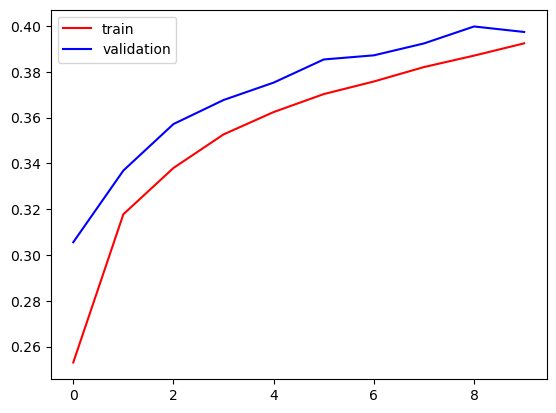

In [10]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

This code plots the training and validation accuracy of the ResNet50-based model across all epochs. The graph helps evaluate learning performance and identify issues such as overfitting or underfitting during training.

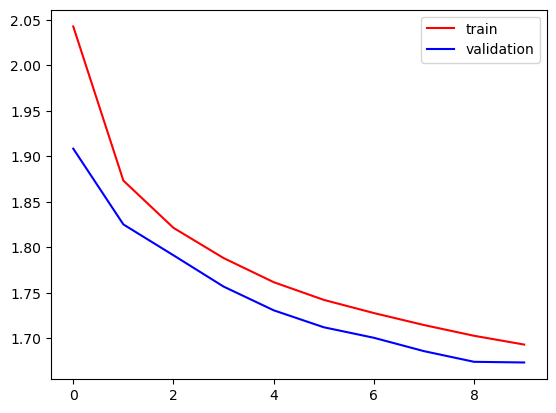

In [11]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

This code visualizes the training and validation loss of the ResNet50-based model over all epochs. The loss curves help evaluate model performance and detect issues such as overfitting or underfitting during training.

### Visualize Convolutional Filters and Feature Maps

This section will visualize the convolutional filters from the initial layers of ResNet50 and then show feature maps generated by a sample image passed through shallow and deep layers of the network. This helps in understanding what features the network is learning.
This code visualizes the learned filters of the first convolution layer and the feature maps generated by shallow and deep layers of ResNet50. It helps analyze how the network progressively transforms raw images into meaningful features for image classification.

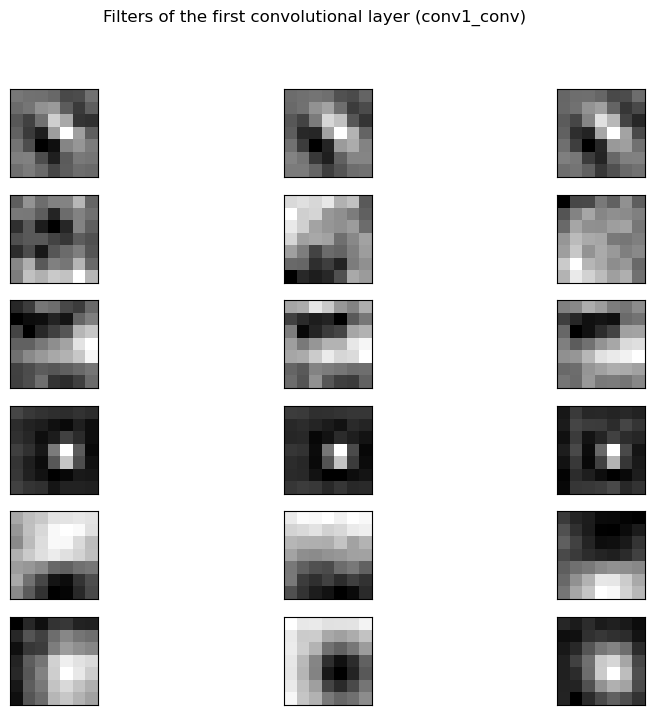

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step


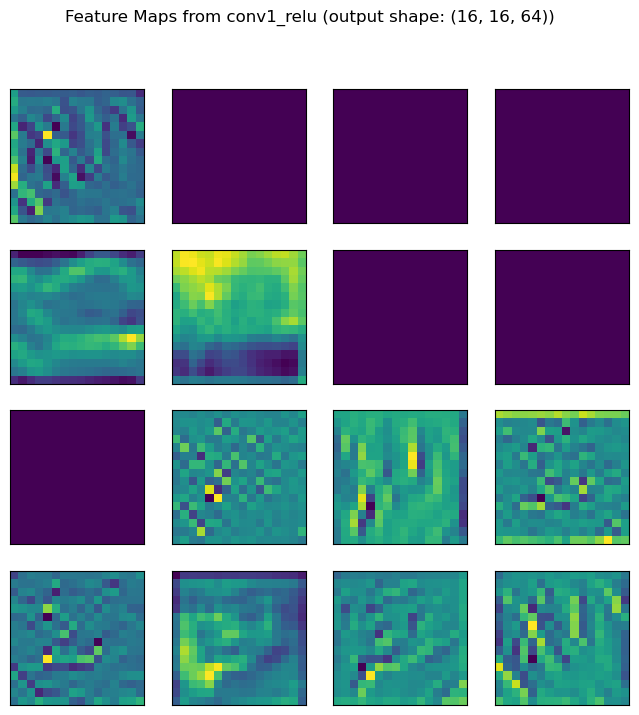

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


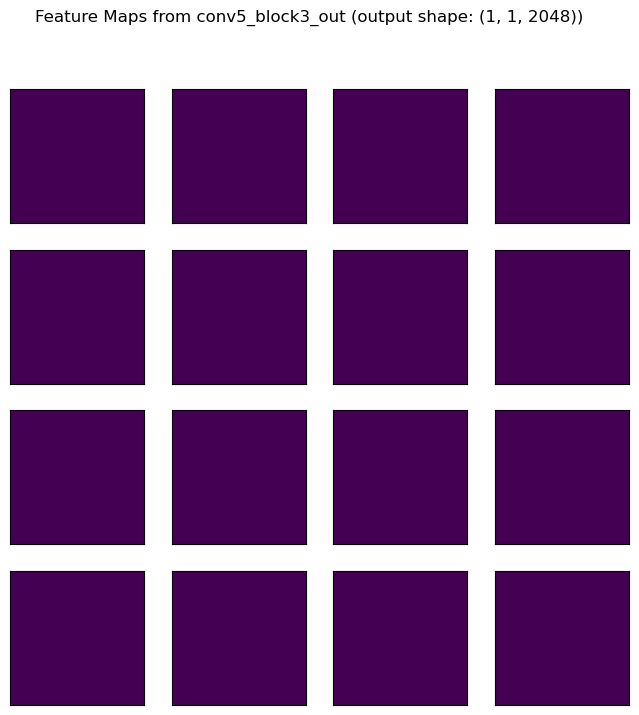

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from keras.models import Model

# Get a sample image from the CIFAR-10 test set
sample_image = X_test[0]
sample_image_batch = np.expand_dims(sample_image, axis=0)

# --- Visualize Filters of the First Convolutional Layer (Example from ResNet50) ---

# The first convolutional layer in ResNet50 is usually named 'conv1_conv'
# Let's try to find it dynamically or use a known name.
# For ResNet50, the initial convolution is often part of 'conv1_conv' or similar in a block.
# A simple way to get filters of an early conv layer is to access the model's layers.

# ResNet50 layers are structured in blocks. 'conv1_conv' is usually the very first conv layer.
# Check the names of the layers in conv_base

first_conv_layer_name = None
for layer in conv_base.layers:
    # ResNet50's first conv layer is typically 'conv1_conv'
    if 'conv1_conv' in layer.name:
        first_conv_layer_name = layer.name
        break

if first_conv_layer_name:
    first_conv_layer = conv_base.get_layer(first_conv_layer_name)
    filters, biases = first_conv_layer.get_weights()

    # Normalize filter values to 0-1 so we can visualize them
    f_min, f_max = filters.min(), filters.max()
    filters = (filters - f_min) / (f_max - f_min)

    # Plot the first few filters
    n_filters, ix = 6, 1 # Plot 6 filters
    plt.figure(figsize=(10, 8))
    for i in range(n_filters):
        # Get the filter
        f = filters[:, :, :, i]
        # Plot each channel separately
        for j in range(3): # Assuming 3 channels (RGB)
            ax = plt.subplot(n_filters, 3, ix)
            ax.set_xticks([])
            ax.set_yticks([])
            plt.imshow(f[:, :, j], cmap='gray')
            ix += 1
    plt.suptitle(f'Filters of the first convolutional layer ({first_conv_layer_name})')
    plt.show()
else:
    print("Could not find the first convolutional layer for filter visualization in ResNet50.")

# --- Visualize Feature Maps ---

# Define layers to extract feature maps from
# Choose a shallow layer (e.g., after the first few blocks) and a deeper layer
# For ResNet50, 'conv1_relu' (output of the first conv block) could be shallow,
# and a layer from 'conv5_block3_out' could be deep.

layer_names = []
# Shallow layer example: After the first activation in conv1 block
if 'conv1_relu' in [layer.name for layer in conv_base.layers]:
    layer_names.append('conv1_relu')
else:
    print("Warning: 'conv1_relu' not found for shallow feature map visualization.")
    # Fallback to another early layer if 'conv1_relu' is not found
    for layer in conv_base.layers:
        if 'conv' in layer.name and 'relu' in layer.name and layer.output.shape[1] > 10: # ensure it's a conv+relu and not too deep
            layer_names.append(layer.name)
            break

# Deep layer example: A layer from the last block, e.g., 'conv5_block3_out'
if 'conv5_block3_out' in [layer.name for layer in conv_base.layers]:
    layer_names.append('conv5_block3_out')
elif 'conv5_block3_2_relu' in [layer.name for layer in conv_base.layers]: # alternative for last relu in conv5
    layer_names.append('conv5_block3_2_relu')
elif 'conv5_block3_out' in [layer.name for layer in conv_base.layers]: # alternative for last relu in conv5
    layer_names.append('conv5_block3_out')
else:
    print("Warning: 'conv5_block3_out' or similar not found for deep feature map visualization.")
    # Fallback to another deep layer if specific not found
    for layer in reversed(conv_base.layers):
        if 'conv' in layer.name and 'relu' in layer.name and layer.output.shape[1] < 10: # ensure it's a conv+relu and deep enough
            layer_names.append(layer.name)
            break

# Create a model that outputs activations for specified layers
activation_models = [Model(inputs=conv_base.inputs, outputs=conv_base.get_layer(name).output) for name in layer_names]

for i, model_act in enumerate(activation_models):
    layer_activation = model_act.predict(sample_image_batch)
    num_filters = layer_activation.shape[-1]

    # Plot only the first 16 feature maps (or fewer if less than 16)
    num_to_plot = min(16, num_filters)
    rows = int(np.sqrt(num_to_plot))
    cols = int(np.ceil(num_to_plot / rows))

    plt.figure(figsize=(cols * 2, rows * 2))
    for filter_idx in range(num_to_plot):
        ax = plt.subplot(rows, cols, filter_idx + 1)
        ax.set_xticks([])
        ax.set_yticks([])
        plt.imshow(layer_activation[0, :, :, filter_idx], cmap='viridis')
    plt.suptitle(f'Feature Maps from {layer_names[i]} (output shape: {layer_activation.shape[1:]})')
    plt.show()

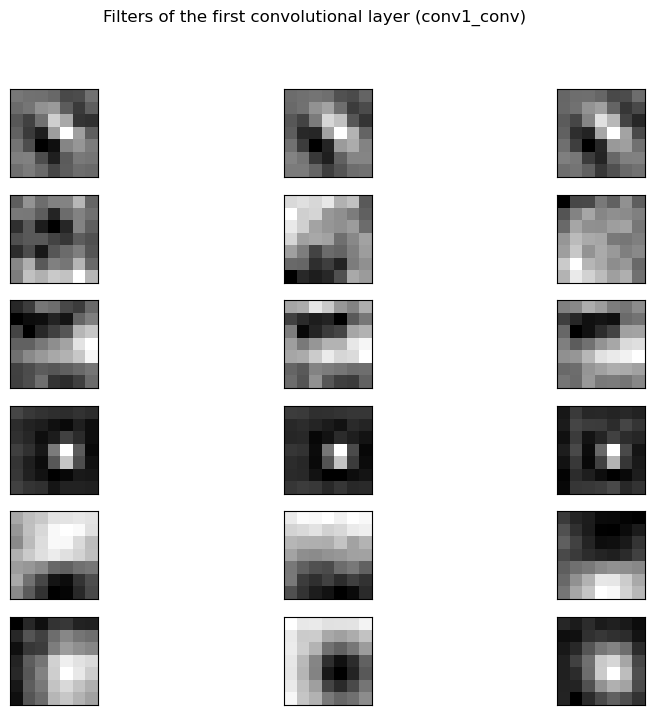

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step


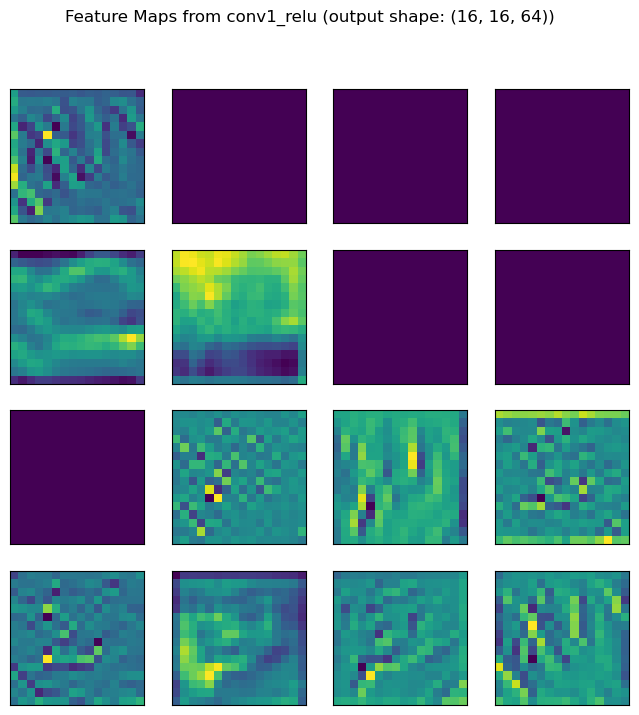

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


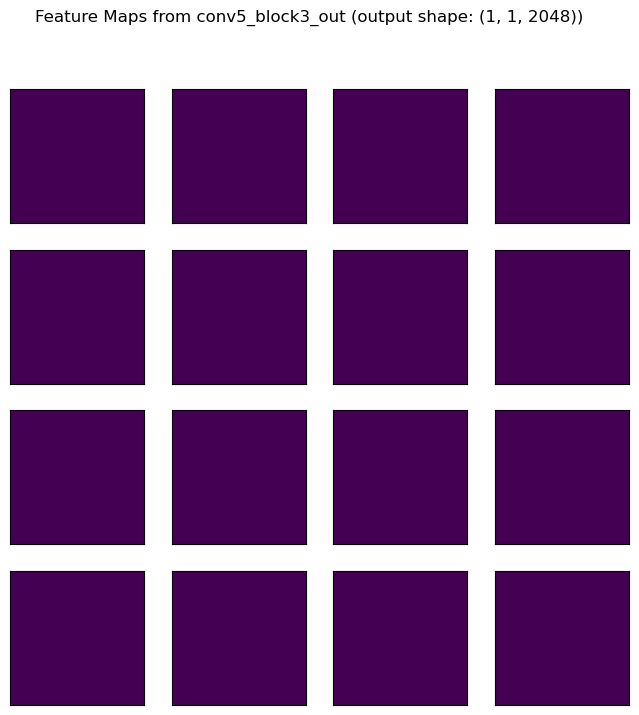

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from keras.models import Model

# Get a sample image from the CIFAR-10 test set
sample_image = X_test[0]
sample_image_batch = np.expand_dims(sample_image, axis=0)

# --- Visualize Filters of the First Convolutional Layer (Example from ResNet50) ---

# The first convolutional layer in ResNet50 is usually named 'conv1_conv'
# Let's try to find it dynamically or use a known name.
# For ResNet50, the initial convolution is often part of 'conv1_conv' or similar in a block.
# A simple way to get filters of an early conv layer is to access the model's layers.

# ResNet50 layers are structured in blocks. 'conv1_conv' is usually the very first conv layer.
# Check the names of the layers in conv_base

first_conv_layer_name = None
for layer in conv_base.layers:
    # ResNet50's first conv layer is typically 'conv1_conv'
    if 'conv1_conv' in layer.name:
        first_conv_layer_name = layer.name
        break

if first_conv_layer_name:
    first_conv_layer = conv_base.get_layer(first_conv_layer_name)
    filters, biases = first_conv_layer.get_weights()

    # Normalize filter values to 0-1 so we can visualize them
    f_min, f_max = filters.min(), filters.max()
    filters = (filters - f_min) / (f_max - f_min)

    # Plot the first few filters
    n_filters, ix = 6, 1 # Plot 6 filters
    plt.figure(figsize=(10, 8))
    for i in range(n_filters):
        # Get the filter
        f = filters[:, :, :, i]
        # Plot each channel separately
        for j in range(3): # Assuming 3 channels (RGB)
            ax = plt.subplot(n_filters, 3, ix)
            ax.set_xticks([])
            ax.set_yticks([])
            plt.imshow(f[:, :, j], cmap='gray')
            ix += 1
    plt.suptitle(f'Filters of the first convolutional layer ({first_conv_layer_name})')
    plt.show()
else:
    print("Could not find the first convolutional layer for filter visualization in ResNet50.")

# --- Visualize Feature Maps ---

# Define layers to extract feature maps from
# Choose a shallow layer (e.g., after the first few blocks) and a deeper layer
# For ResNet50, 'conv1_relu' (output of the first conv block) could be shallow,
# and a layer from 'conv5_block3_out' could be deep.

layer_names = []
# Shallow layer example: After the first activation in conv1 block
if 'conv1_relu' in [layer.name for layer in conv_base.layers]:
    layer_names.append('conv1_relu')
else:
    print("Warning: 'conv1_relu' not found for shallow feature map visualization.")
    # Fallback to another early layer if 'conv1_relu' is not found
    for layer in conv_base.layers:
        if 'conv' in layer.name and 'relu' in layer.name and layer.output.shape[1] > 10: # ensure it's a conv+relu and not too deep
            layer_names.append(layer.name)
            break

# Deep layer example: A layer from the last block, e.g., 'conv5_block3_out'
if 'conv5_block3_out' in [layer.name for layer in conv_base.layers]:
    layer_names.append('conv5_block3_out')
elif 'conv5_block3_2_relu' in [layer.name for layer in conv_base.layers]: # alternative for last relu in conv5
    layer_names.append('conv5_block3_2_relu')
elif 'conv5_block3_out' in [layer.name for layer in conv_base.layers]: # alternative for last relu in conv5
    layer_names.append('conv5_block3_out')
else:
    print("Warning: 'conv5_block3_out' or similar not found for deep feature map visualization.")
    # Fallback to another deep layer if specific not found
    for layer in reversed(conv_base.layers):
        if 'conv' in layer.name and 'relu' in layer.name and layer.output.shape[1] < 10: # ensure it's a conv+relu and deep enough
            layer_names.append(layer.name)
            break

# Create a model that outputs activations for specified layers
activation_models = [Model(inputs=conv_base.inputs, outputs=conv_base.get_layer(name).output) for name in layer_names]

for i, model_act in enumerate(activation_models):
    layer_activation = model_act.predict(sample_image_batch)
    num_filters = layer_activation.shape[-1]

    # Plot only the first 16 feature maps (or fewer if less than 16)
    num_to_plot = min(16, num_filters)
    rows = int(np.sqrt(num_to_plot))
    cols = int(np.ceil(num_to_plot / rows))

    plt.figure(figsize=(cols * 2, rows * 2))
    for filter_idx in range(num_to_plot):
        ax = plt.subplot(rows, cols, filter_idx + 1)
        ax.set_xticks([])
        ax.set_yticks([])
        plt.imshow(layer_activation[0, :, :, filter_idx], cmap='viridis')
    plt.suptitle(f'Feature Maps from {layer_names[i]} (output shape: {layer_activation.shape[1:]})')
    plt.show()